# 04. Results and Model Comparison

Research question: does a classical, statically-calibrated pairs-trading strategy on the 2024
cryptocurrency spot universe produce a positive risk-adjusted return out-of-sample? This
notebook is the single cleanest artifact for an external reviewer -- it loads the standardized
summary rows already computed in notebooks 01 and 03 (no strategy implementation code is
duplicated here) and reports the full model comparison, limitations, and conclusions.

**Model registry** (see `CLAUDE.md` for full detail):

| ID | Description |
|---|---|
| `S0_STATIC_BASELINE` | Frozen static pairs, one global time stop -- the control model |
| `S1_STATIC_PAIR_HALFLIFE_STOP` | S0 + per-pair time stop = ceil(2.5x formation half-life) |
| `WF1_SEMIANNUAL_REESTIMATION` | Walk-forward pair re-selection, 12mo formation / 6mo rebalance |
| `WF2_ROLLING_ENTRY_HEDGE_RATIO` | WF1 + rolling entry-time hedge sizing (signal still frozen formation alpha/beta) |

**Research-scope disclaimer:** this is a research-learning project, not a production trading
strategy -- simplified short-leg implementation, no funding/borrow/margin modeling, Binance spot
reference prices.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for _p in (PROJECT_ROOT, PROJECT_ROOT / 'src'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.research_config import (CONFIG, WF_CONFIG, MAX_HALF_LIFE_BARS, MIN_CROSSINGS, MODEL_IDS,
                                     S1_TIME_STOP_MULTIPLIER, S1_TIME_STOP_MULTIPLIER_ROBUSTNESS,
                                     FORWARD_EVAL_START)

In [2]:
results_tables_dir = PROJECT_ROOT / 'results' / 'tables'
with open(results_tables_dir / 's0_s1_rows.json') as f:
    s0_s1 = json.load(f)
with open(results_tables_dir / 'wf1_wf2_rows.json') as f:
    wf1_wf2 = json.load(f)

MASTER_COMPARISON_DF = pd.DataFrame([
    s0_s1['S0_STATIC_BASELINE'], s0_s1['S1_STATIC_PAIR_HALFLIFE_STOP'],
    wf1_wf2['WF1_SEMIANNUAL_REESTIMATION'], wf1_wf2['WF2_ROLLING_ENTRY_HEDGE_RATIO'],
]).set_index('model')
print('Master model comparison -- OOS (2024-01-01 to 2026-06-30):')
MASTER_COMPARISON_DF.round(4).T

Master model comparison -- OOS (2024-01-01 to 2026-06-30):


model,S0_STATIC_BASELINE,S1_STATIC_PAIR_HALFLIFE_STOP,WF1_SEMIANNUAL_REESTIMATION,WF2_ROLLING_ENTRY_HEDGE_RATIO
daily_sharpe_252,-0.1155,-0.1249,-0.0679,-0.0185
bar_sharpe_secondary,-0.1528,-0.1613,NaN,NaN
ann_volatility,0.0387,0.0416,0.0931,0.0854
cum_net_return,-0.0165,-0.0188,-0.0380,-0.0188
cum_gross_return,-0.0072,-0.0092,-0.0299,-0.0107
max_drawdown,-0.1117,-0.1053,-0.1858,-0.1563
n_trades,29.0000,29.0000,2.0000,2.0000
n_pairs_traded,11.0000,11.0000,1.0000,1.0000
win_rate,0.4828,0.5517,0.5000,0.5000
avg_trade_return,-0.0024,0.0013,-0.0129,-0.0040


## Standardized comparison fields

`daily_sharpe_252`, `ann_volatility` (both via the daily-252 convention -- see `CLAUDE.md`
"Evaluation conventions"), `cum_net_return`, `max_drawdown`, `n_trades`, `time_in_market_pct`,
`turnover`, `total_costs_pct`, `btc_correlation`, `btc_beta`, `ann_alpha`, `alpha_tstat_ols`,
`alpha_tstat_hac`, `r_squared` -- all four models report through the exact same schema
(`standardized_model_summary`/`standardized_wf1_summary` in `stat_arb.reporting`).

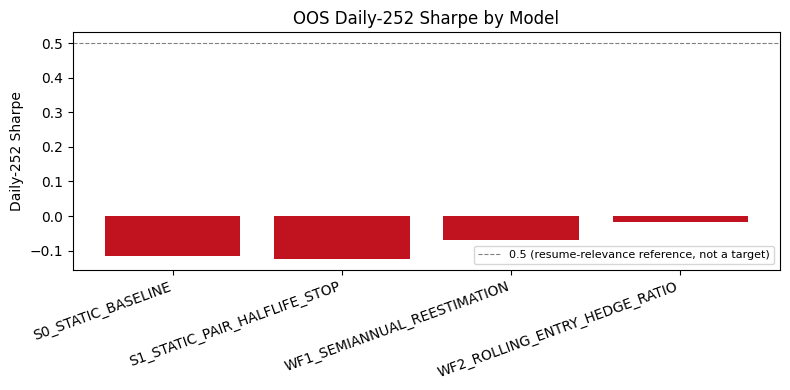

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sharpes = MASTER_COMPARISON_DF['daily_sharpe_252']
colors = ['#2a6f97' if v >= 0 else '#c1121f' for v in sharpes]
ax.bar(sharpes.index, sharpes.values, color=colors)
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8, label='0.5 (resume-relevance reference, not a target)')
ax.set_ylabel('Daily-252 Sharpe')
ax.set_title('OOS Daily-252 Sharpe by Model')
ax.legend(fontsize=8)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## Evaluation-Period Labelling

Every model above is reported over 2024-01-01 to 2026-06-30, labelled throughout this project
as a **Post-Sample Historical Evaluation** (see notebook 01's "Note on the Final OOS label") --
a corrected historical re-evaluation under a fixed, pre-specified methodology, not a pristine
never-seen holdout. `FORWARD_EVAL_START` marks the genuinely untouched forward window: no
parameter anywhere in `config/research_config.py` has been set or changed using any data at or
after this date, and none may be in the future without that constituting a new, explicitly
labelled research iteration.

In [4]:
from stat_arb.data import load_raw_prices

_px_check = load_raw_prices()
assert _px_check.index.max() < pd.Timestamp(FORWARD_EVAL_START), (
    'px.pkl already contains data at or after FORWARD_EVAL_START -- the forward-evaluation '
    'window is no longer untouched and this constant must be moved forward before any further '
    'model change is made.')
print(f'[CHECK] No data currently available at or after FORWARD_EVAL_START ({FORWARD_EVAL_START}) -- '
      f'the forward-evaluation window remains genuinely unstarted. Data ends {_px_check.index.max()}.')

[CHECK] No data currently available at or after FORWARD_EVAL_START (2026-07-01) -- the forward-evaluation window remains genuinely unstarted. Data ends 2026-06-30 00:00:00.


## Limitations

- **S0/S1 OOS Sharpe and cumulative return are both negative** on this sample -- a negative
  result is an acceptable, reportable outcome, not a failure of the research process.
- **S1's time-stop multiplier robustness is unstable** (2.0x/2.5x/3.0x Sharpe swings materially,
  see notebook 01) -- the time-stop choice does not robustly explain S0's underperformance.
- **WF1/WF2 trade only a handful of times** in the full OOS window (see notebook 03) -- any
  comparison against S0/S1, or between WF1 and WF2, must state this sample-size limitation.
- **WF1's active-day BTC beta materially exceeds its unconditional beta** (notebook 03) --
  low time-in-market makes the unconditional beta an unreliable market-neutrality indicator.
- This is a research-learning project: simplified short-leg implementation, no funding/borrow/
  margin modeling, Binance spot reference prices -- not a production P&L estimate.

## Final Research Interpretation

None of the four model versions produced a robustly positive, statistically well-supported
Sharpe ratio on this out-of-sample window. S0/S1 (negative Sharpe, unstable time-stop
robustness) and WF1/WF2 (too few trades for a reliable conclusion, and not market-neutral on
the days they do trade) each fail to clear the ~0.5 Sharpe resume-relevance threshold. This is
reported as the honest outcome of a pre-specified, no-look-ahead, non-overfit research process
-- not as a basis for further parameter searching on this same OOS window.